In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

wine = load_wine()

df = pd.DataFrame(
    wine.data,
    columns=wine.feature_names
)

df['class'] = wine.target

print("Dataset Shape:", df.shape)
print("\nFirst five rows:")
display(df.head())

print("\nClass names:", wine.target_names)


Dataset Shape: (178, 14)

First five rows:


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,class
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0



Class names: ['class_0' 'class_1' 'class_2']


# Basic Statistics

In [ ]:
print("Basic statistics of the dataset:")
display(df.describe())

Basic statistics of the dataset:


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,class
count,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000
mean,13.000618,2.336348,2.366517,19.494944,99.741573,2.295112,2.029270,0.361854,1.590899,5.058090,0.957449,2.611685,746.893258,0.938202
std,0.811827,1.117146,0.274344,3.339564,14.282484,0.625851,0.998859,0.124453,0.572359,2.318286,0.228572,0.709990,314.907474,0.775035
min,11.030000,0.740000,1.360000,10.600000,70.000000,0.980000,0.340000,0.130000,0.410000,1.280000,0.480000,1.270000,278.000000,0.000000
25%,12.362500,1.602500,2.210000,17.200000,88.000000,1.742500,1.205000,0.270000,1.250000,3.220000,0.782500,1.937500,500.500000,0.000000
50%,13.050000,1.865000,2.360000,19.500000,98.000000,2.355000,2.135000,0.340000,1.555000,4.690000,0.965000,2.780000,673.500000,1.000000
75%,13.677500,3.082500,2.557500,21.500000,107.000000,2.800000,2.875000,0.437500,1.950000,6.200000,1.120000,3.170000,985.000000,2.000000
max,14.830000,5.800000,3.230000,30.000000,162.000000,3.880000,5.080000,0.660000,3.580000,13.000000,1.710000,4.000000,1680.000000,2.000000


# Boxplot

<Figure size 800x500 with 0 Axes>

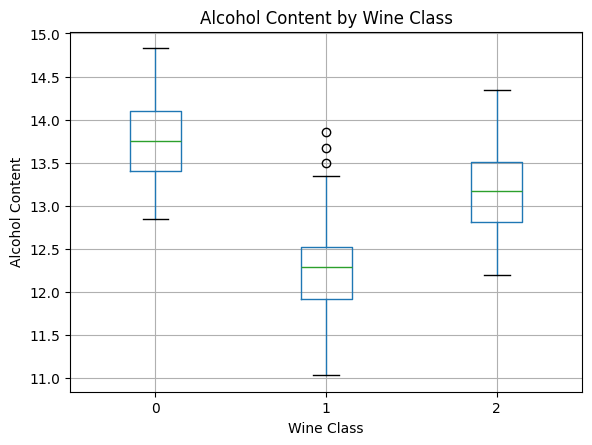

In [ ]:
plt.figure(figsize=(8, 5))

df.boxplot(column='alcohol', by='class')

plt.title('Alcohol Content by Wine Class')
plt.suptitle('')
plt.xlabel('Wine Class')
plt.ylabel('Alcohol Content')
plt.show()

The boxplot compares the distribution of alcohol content across the three wine classes. Differences in medians and spreads indicate that alcohol content varies between classes. The plot also helps identify possible outliers.

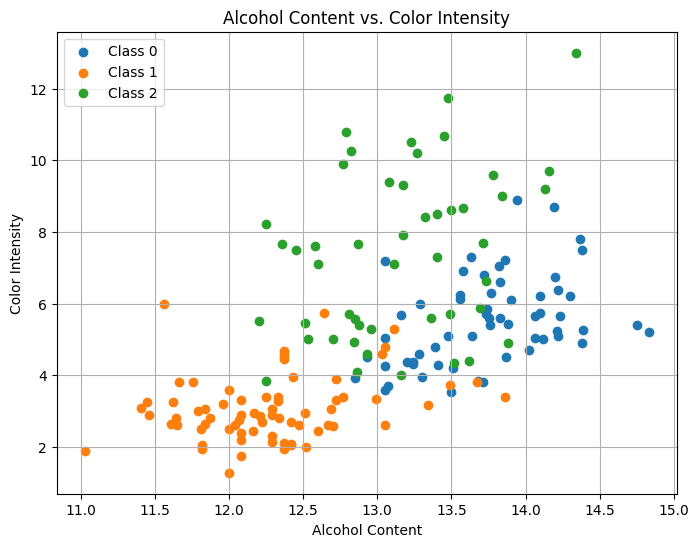

In [ ]:
plt.figure(figsize=(8, 6))

for cls in sorted(df['class'].unique()):
  subset = df[df['class'] == cls]

  plt.scatter(
      subset['alcohol'],
      subset['color_intensity'],
      label=f'Class {cls}'
  )

plt.title('Alcohol Content vs. Color Intensity')
plt.xlabel('Alcohol Content')
plt.ylabel('Color Intensity')
plt.legend()
plt.grid(True)
plt.show()




The scatterplot illustrates the relationship between alcohol content and color intensity. The different colors represent the three wine classes. The plot helps identify patterns, relationships, and potential separation between classes using these two features.

Covariance Matrix:


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
alcohol,0.659062,0.085611,0.047115,-0.841093,3.139878,0.146887,0.192033,-0.015754,0.063518,1.028283,-0.013313,0.041698,164.567185
malic_acid,0.085611,1.248015,0.050277,1.076332,-0.870780,-0.234338,-0.458630,0.040733,-0.141147,0.644838,-0.143326,-0.292447,-67.548867
ash,0.047115,0.050277,0.075265,0.406208,1.122937,0.022146,0.031535,0.006358,0.001516,0.164654,-0.004682,0.000762,19.319739
alcalinity_of_ash,-0.841093,1.076332,0.406208,11.152686,-3.974760,-0.671149,-1.172083,0.150422,-0.377176,0.145024,-0.209118,-0.656234,-463.355345
magnesium,3.139878,-0.870780,1.122937,-3.974760,203.989335,1.916470,2.793087,-0.455563,1.932832,6.620521,0.180851,0.669308,1769.158700
total_phenols,0.146887,-0.234338,0.022146,-0.671149,1.916470,0.391690,0.540470,-0.035045,0.219373,-0.079998,0.062039,0.311021,98.171057
flavanoids,0.192033,-0.458630,0.031535,-1.172083,2.793087,0.540470,0.997719,-0.066867,0.373148,-0.399169,0.124082,0.558262,155.447492
nonflavanoid_phenols,-0.015754,0.040733,0.006358,0.150422,-0.455563,-0.035045,-0.066867,0.015489,-0.026060,0.040121,-0.007471,-0.044469,-12.203586
proanthocyanins,0.063518,-0.141147,0.001516,-0.377176,1.932832,0.219373,0.373148,-0.026060,0.327595,-0.033504,0.038665,0.210933,59.554334
color_intensity,1.028283,0.644838,0.164654,0.145024,6.620521,-0.079998,-0.399169,0.040121,-0.033504,5.374449,-0.276506,-0.705813,230.767480


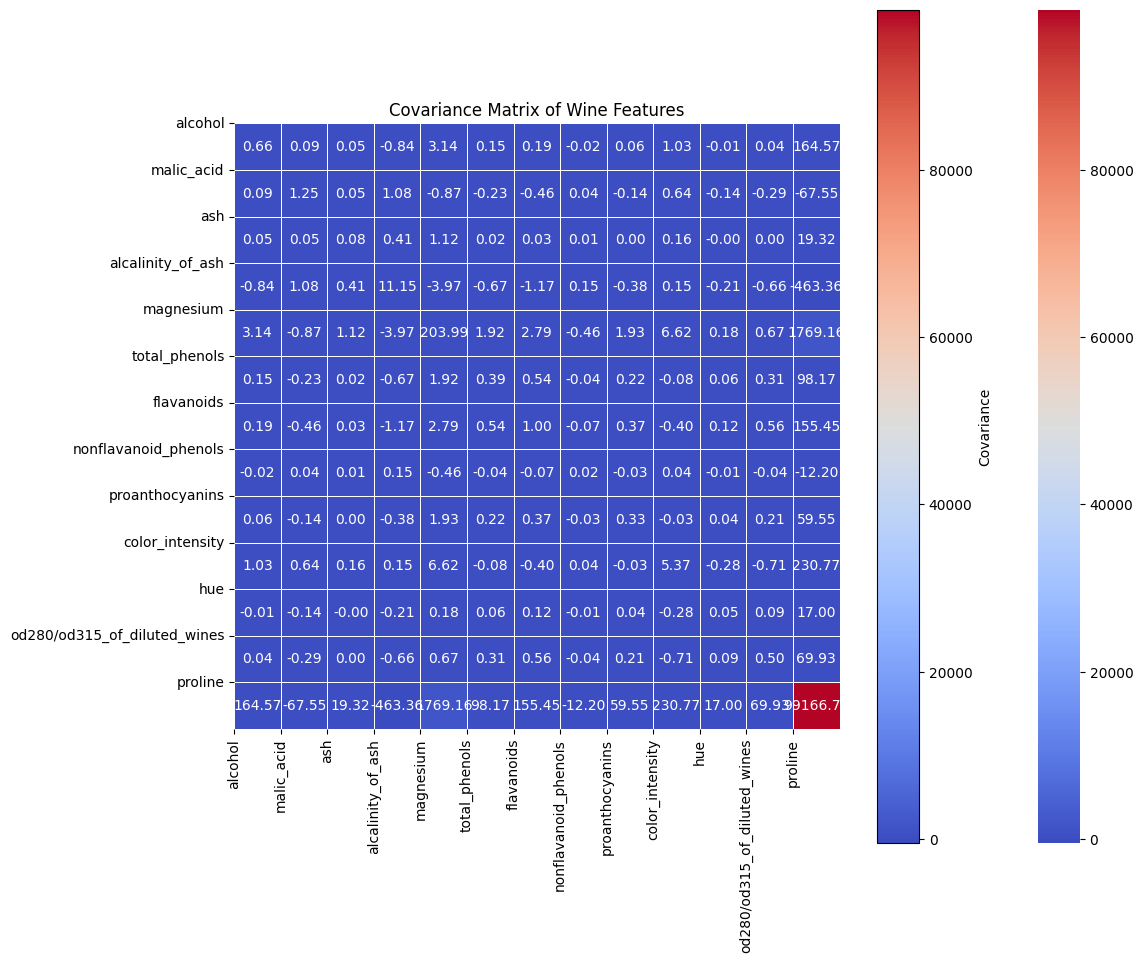

In [ ]:

cov_matrix = df.drop(columns='class').cov()

print("Covariance Matrix:")
display(cov_matrix)

plt.figure(figsize=(12, 10))
sns.heatmap(
    cov_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    linewidths=0.5
)

plt.imshow(cov_matrix, cmap='coolwarm')
plt.colorbar(label='Covariance')

plt.xticks(
    range(len(cov_matrix.columns)),
    cov_matrix.columns,
    rotation=90
)

plt.yticks(
    range(len(cov_matrix.columns)),
    cov_matrix.columns
)

plt.title('Covariance Matrix of Wine Features')
plt.tight_layout()
plt.show()


The covariance matrix represents the relationships between the numerical features of the Wine dataset. Positive values indicate that two variables tend to vary in the same direction, while negative values indicate that they tend to vary in opposite directions.

The magnitude of covariance depends on the scales of the variables, so covariance values should be interpreted carefully.

In [ ]:
X = df.drop(columns='class')
y = df['class']

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

X_scaled_df = pd.DataFrame(
    X_scaled,
    columns=X.columns
)

print("Scaled dataset:")
display(X_scaled_df.head())

print("\nMean after scaling:")
print(X_scaled_df.mean().round(2))

print("\nStandard deviation after scaling:")
print(X_scaled_df.std().round(2))


In [ ]:
pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

pca_df = pd.DataFrame(
    X_pca,
    columns=['Principal Component 1',
             'Principal Component 2']
)

pca_df['class'] = y

print("PCA Results:")
display(pca_df.head())

print("\nExplained variance ratio:")
print(pca.explained_variance_ratio_)

print("\nTotal variance explained:")
print(pca.explained_variance_ratio_.sum())


In [ ]:
plt.figure(figsize=(10, 7))

for cls in sorted(pca_df['class'].unique()):
    subset = pca_df[pca_df['class'] == cls]

    plt.scatter(
        subset['Principal Component 1'],
        subset['Principal Component 2'],
        label=f'Class {cls}',
        alpha=0.8
    )

plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')

plt.title('PCA: Wine Dataset Class Separation')

plt.legend()
plt.grid(True)
plt.show()


PCA reduced the original 13-dimensional Wine dataset to two principal components. The scatterplot shows the distribution of the three wine classes in the reduced feature space.

The principal components retain as much variance as possible for a two-dimensional representation. The visualization may reveal better separation between wine classes, although PCA maximizes variance rather than directly optimizing class separation.